### 🎯 프로젝트 **목표**

- 이번 과제는 단순히 모델을 구현하는 데서 끝나는 것이 아니라, **기존 Baseline 모델의 한계를 스스로 파악하고 더 나은 방향으로 개선해보는 과정 자체**를 경험하는 데 목적이 있습니다.
- 다양한 실험과 비교를 통해, 하나의 정답을 찾기보다 **문제를 정의하고 가설을 세우고 검증하는 문제 해결 과정**을 직접 연습해보는 것이 중요합니다.
- 이번 과제는 여러분이 지금까지 배운 내용을 바탕으로 진행되지만, **필요하다면 배우지 않은 내용도 스스로 찾아보고 적용해보는 경험**까지 포함합니다.
- 성능 수치만 높이는 것이 아니라, **왜 이런 전략을 선택했는지, 어떤 실험이 효과가 있었는지, 어떤 실패를 통해 무엇을 배웠는지**까지 함께 정리해보며 한 단계 더 성장해보는 것을 목표로 합니다.
- 익숙한 방법만 반복하는 것이 아니라, 새로운 방법을 시도해보며 스스로 탐색하는 과정도 중요한 학습입니다.

## ⚠️ 과제 수행 필수 규칙

1. **사전 학습된(Pre-trained) 모델 활용 시**
    - **최소 2개 이상의 개선 전략 적용**
        - 단순 모델 변경 외에 추가적인 시도(전처리, Loss 조정, optimizer 변경, learning rate 조정 등)가 필수입니다.
        - **Baseline 대비 의미 있는 성능 비교 결과를 반드시 포함**해야 합니다.(단, 개선 폭이 크지 않더라도 실험 과정과 분석이 충분히 설명되면 평가에 반영됩니다.)
    - 왜 해당 모델을 선택하였으며 문제 해결에 적합하다고 생각했는지 명시하세요.
    - **Fine-tuning 방식**에서 어떤 부분을 고정하고, 어떤 부분을 학습했는지, 왜 그렇게 설정했는지 구체적으로 작성해주세요.
        1. **논리적 근거 제시**
            - 모델 선정 시 “좋아보여서”가 아닌 왜 현재 문제에 해당 모델이 적합했는지를 명시해주세요.
            - **AI 도구 사용은 가능**하지만, 왜 그 방법을 썼는지 본인의 언어로 설명할 수 있어야 합니다.
    - 단, **단순 적용만으로는 성능 개선으로 인정되지 않습니다.**
2. **재현성 확보**
    - 제출한 코드는 누구나 실행했을 때 동일한 결과가 나와야 하는 전체 파이프라인 형태여야 합니다.
3. **데일리 로그**
    - 매일의 진행 과정과 고민의 흔적을 기록으로 남깁니다.
          
4. **과제 태도**
    - 수업에서 다루지 않았더라도, 문제 해결에 필요하다고 판단한 방법은 충분히 탐색하고 시도해보세요.
    - 이번 과제에서는 **배운 내용만 반복하는 것보다, 필요한 내용을 스스로 찾아보고 적용해보는 태도**도 중요합니다.

# Mission 0. 문제 해결 전략 수립 (Flow Planning)

## 1. 문제 정의
- 과제: 흉부 X-ray 영상을 정상(0)과 폐렴(1)으로 구분하는 이진 분류
- 데이터: train 5,216장 (정상 26%, 폐렴 74%로 불균형), test 624장 (label 없음)
- 임상적 의미: 폐렴을 놓치는 위음성이 정상을 폐렴으로 보는 위양성보다 위험하다.
  그래서 Accuracy를 주 지표로 쓰되, Recall(민감도)과 Specificity(특이도)를 함께 확인한다.

## 2. 전체 흐름
1) 데이터 확인: train, test 데이터의 형태와 이미지 특성 확인
2) 학습 준비: seed 고정, 층화 분할, 데이터셋 구성, 평가 지표
3) Baseline 구축: 단순한 CNN + 기본 설정
4) 한계 진단: 혼동행렬, 학습 곡선(과적합), Grad-CAM
5) 가설 수립 및 개선 실험: 한 번에 하나씩 변경 (예: 불균형 보정, 데이터 증강, ResNet50 전이학습/Fine-tuning)
6) 결과 비교와 해석: 성공, 실패 모두 기록
7) 최종 모델 선정 및 재현성 검증
8) 제출

# 1. 데이터 확인
1) 라이브러리, 경로 설정
2) train CSV 확인
3) train 이미지 확인
4) test 데이터 확인

In [17]:
# 라이브러리 호출
import os                                             # 파일 경로, 폴더 접근
import random                                         # seed 고정
import numpy as np                                    # 숫자 배열 계산
import pandas as pd                                   # 표 데이터(csv) 처리
import matplotlib.pyplot as plt                       # 이미지, 그래프 시각화
from PIL import Image                                 # 이미지 파일 열기

import torch                                          # 딥러닝 핵심 라이브러리
import torch.nn as nn                                 # 신경망 층, 손실함수
import torch.optim as optim                           # 최적화 (Adam)
from torch.utils.data import Dataset, DataLoader      # 데이터셋, 배치 구성
from torchvision import transforms                    # 이미지 → 텐서 변환

from sklearn.model_selection import train_test_split  # 학습/검증 데이터 분할
from sklearn import metrics                           # 평가 지표

print("torch:", torch.__version__)                    # 버전 기록 (재현성)

torch: 2.14.1


In [18]:
# 경로 지정
BASE_DIR      = "/Users/mac/Desktop/deep_learning/chest_xray"   # 이 줄만 각자 환경에 맞게 수정
TRAIN_CSV     = os.path.join(BASE_DIR, "train.csv")
TRAIN_DIR     = os.path.join(BASE_DIR, "train")
TEST_CSV      = os.path.join(BASE_DIR, "test.csv")
TEST_DIR      = os.path.join(BASE_DIR, "test")
SUBMIT_CSV    = os.path.join(BASE_DIR, "sample_submission.csv")

for path in [TRAIN_CSV, TRAIN_DIR, TEST_CSV, TEST_DIR, SUBMIT_CSV]:
    print(os.path.exists(path), path)

True /Users/mac/Desktop/deep_learning/chest_xray/train.csv
True /Users/mac/Desktop/deep_learning/chest_xray/train
True /Users/mac/Desktop/deep_learning/chest_xray/test.csv
True /Users/mac/Desktop/deep_learning/chest_xray/test
True /Users/mac/Desktop/deep_learning/chest_xray/sample_submission.csv


In [19]:
# 1-2) train CSV 확인
df = pd.read_csv(TRAIN_CSV)

print("데이터 크기:", df.shape)
print(df.head())
print("결측치:\n", df.isnull().sum())
print("중복 파일명:", df['file_name'].duplicated().sum())
print("라벨 분포:\n", df['label'].value_counts())
print("라벨 비율:\n", df['label'].value_counts(normalize=True).round(2))

# CSV와 이미지 폴더 일치 확인
train_files = [f for f in os.listdir(TRAIN_DIR) if f.endswith(".png")]
print("이미지 파일 수:", len(train_files))
print("CSV에는 있으나 폴더에 없는 파일:", len(set(df['file_name']) - set(train_files)))
print("폴더에는 있으나 CSV에 없는 파일:", len(set(train_files) - set(df['file_name'])))

데이터 크기: (5216, 2)
        file_name  label
0  train_0001.png      0
1  train_0002.png      0
2  train_0003.png      0
3  train_0004.png      0
4  train_0005.png      0
결측치:
 file_name    0
label        0
dtype: int64
중복 파일명: 0
라벨 분포:
 label
1    3875
0    1341
Name: count, dtype: int64
라벨 비율:
 label
1    0.74
0    0.26
Name: proportion, dtype: float64
이미지 파일 수: 5216
CSV에는 있으나 폴더에 없는 파일: 0
폴더에는 있으나 CSV에 없는 파일: 0


In [20]:
# 1-3) train 이미지 확인

# 전체 이미지 경로 만들기 (폴더 경로 + 파일 이름)
df['image_path'] = [os.path.join(TRAIN_DIR, f) for f in df['file_name']]

# 샘플 이미지 1장: 숫자 배열로 확인
sample = np.array(Image.open(df['image_path'][0]))
print("배열 형태:", sample.shape, "/ 자료형:", sample.dtype, "/ 픽셀값 범위:", sample.min(), "~", sample.max())

# 전체 이미지: 크기와 색 형식 확인
img_info = []
for path in df['image_path']:
    with Image.open(path) as im:
        img_info.append((im.size, im.mode))
print("(크기, 색 형식)별 개수:\n", pd.Series(img_info).value_counts())

배열 형태: (224, 224) / 자료형: uint8 / 픽셀값 범위: 0 ~ 250
(크기, 색 형식)별 개수:
 ((224, 224), L)    5216
Name: count, dtype: int64


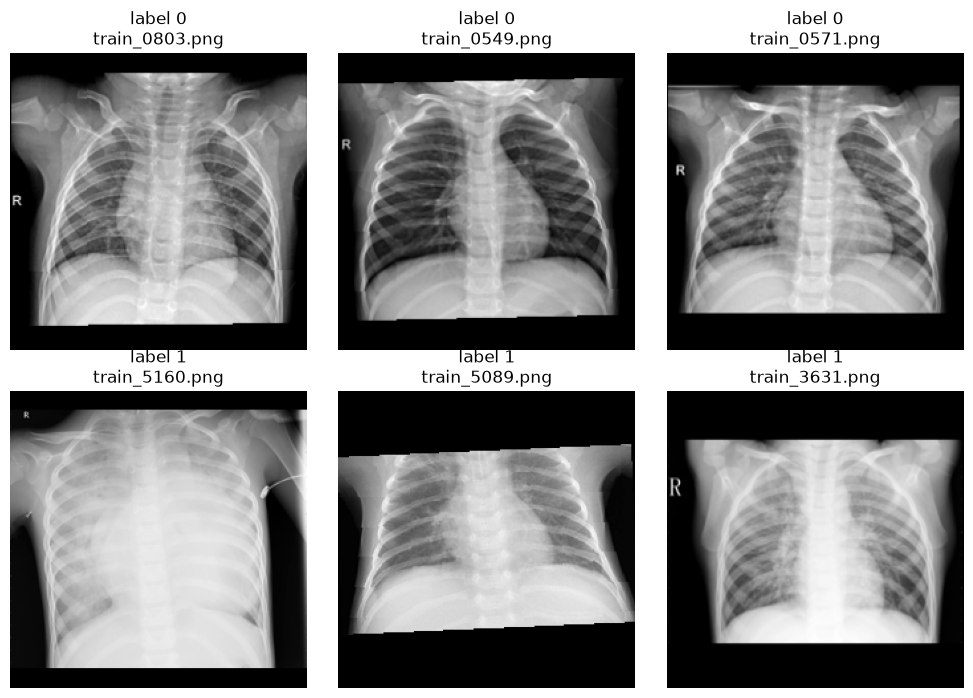

In [21]:
# 라벨별 샘플 이미지 비교 (윗줄: 정상 0, 아랫줄: 폐렴 1)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for row, label in enumerate([0, 1]):
    paths = df[df['label'] == label]['image_path'].sample(3, random_state=42)
    for col, path in enumerate(paths):
        axes[row, col].imshow(Image.open(path), cmap='gray')
        axes[row, col].set_title(f"label {label}\n{os.path.basename(path)}")
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

In [22]:
# 1-4) test 데이터 확인
test_df   = pd.read_csv(TEST_CSV)
submit_df = pd.read_csv(SUBMIT_CSV)
test_df['image_path'] = [os.path.join(TEST_DIR, f) for f in test_df['file_name']]

print("test.csv:", test_df.shape, list(test_df.columns))
print("sample_submission.csv:", submit_df.shape, list(submit_df.columns))
print("test와 제출 양식의 파일 순서 일치:", (test_df['file_name'] == submit_df['file_name']).all())

test_files = [f for f in os.listdir(TEST_DIR) if f.endswith(".png")]
print("test 이미지 수:", len(test_files))
print("CSV-폴더 불일치 파일 수:", len(set(test_df['file_name']) ^ set(test_files)))

# test 이미지 전체의 크기, 색 형식 확인 (train과 같은지)
test_info = []
for path in test_df['image_path']:
    with Image.open(path) as im:
        test_info.append((im.size, im.mode))
test_info = pd.Series(test_info)
print("서로 다른 (크기, 색 형식) 종류 수:", test_info.nunique())
print(test_info.value_counts().head())

test.csv: (624, 2) ['file_name', 'image_path']
sample_submission.csv: (624, 2) ['file_name', 'label']
test와 제출 양식의 파일 순서 일치: True
test 이미지 수: 624
CSV-폴더 불일치 파일 수: 0
서로 다른 (크기, 색 형식) 종류 수: 598
((1112, 736), L)    3
((1088, 576), L)    2
((1368, 904), L)    2
((1112, 600), L)    2
((1232, 888), L)    2
Name: count, dtype: int64


## 1-5) 데이터 확인 결과

1) train CSV
- 5,216개, 2개 컬럼 (file_name, label), 결측치와 중복 없음
- label: 0(정상) 1,341개(26%), 1(폐렴) 3,875개(74%) → 불균형
- CSV와 이미지 파일이 정확히 일치

2) train 이미지
- 전체 224×224, 흑백(L, 1채널), uint8 (픽셀값 0~255, 0: 검정, 255: 흰색)
- 라벨 1(폐렴) 영상에서 폐야의 음영 증가 확인
- 특이 사항: 가장자리 검은 여백, 일부 회전된 영상, R 표시와 전극선 등 이물질

3) test 데이터
- 624개, file_name만 있음 (label 없음)
- 제출 양식: file_name, label(0 또는 1)
- test 이미지는 224×224가 아니라 크기가 제각각 (train만 미리 224로 맞춰져 있음)

4) 시사점
- 불균형 → 층화 분할 필요, 모두 폐렴으로 예측해도 Accuracy 74%이므로 보조 지표 필요
- test는 train과 같은 방식(비율 유지 + 검은 여백)으로 224×224로 맞춤, 픽셀값은 0~1로 스케일링
- 모델이 여백, R 표시, 전극선을 단서로 학습할 위험 → Grad-CAM으로 확인
- ResNet50 사용 시 1채널 → 3채널 복제 필요

# 2. 학습 준비
1) 재현성 확보: seed 고정, 연산 장치 설정
2) 데이터 분할: 학습:검증 = 8:2, label 비율 유지(stratify)
3) 데이터셋 구성: Dataset, DataLoader
4) 평가 지표: Accuracy(주 지표), Recall(민감도), Specificity(특이도), F1, AUC

In [23]:
# 2-1) 재현성 확보
SEED = 42

def set_seed(seed):
    random.seed(seed)          # 파이썬 랜덤
    np.random.seed(seed)       # NumPy 랜덤
    torch.manual_seed(seed)    # PyTorch 랜덤 (가중치 초기값 등)

set_seed(SEED)

# 연산 장치 (cuda: NVIDIA GPU, mps: Mac GPU, 없으면 cpu)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("사용 장치:", device)

사용 장치: mps


In [24]:
# 2-2) 데이터 분할 (층화 분할)
x_train, x_val, y_train, y_val = train_test_split(
    df['image_path'], df['label'],
    test_size=0.2,          # 학습 80%, 검증 20%
    stratify=df['label'],   # label 비율 유지
    random_state=SEED       # 매번 같은 분할
)

print("학습:", len(x_train), "/ 검증:", len(x_val))
print("학습 라벨 비율:", y_train.value_counts(normalize=True).round(3).to_dict())
print("검증 라벨 비율:", y_val.value_counts(normalize=True).round(3).to_dict())

학습: 4172 / 검증: 1044
학습 라벨 비율: {1: 0.743, 0: 0.257}
검증 라벨 비율: {1: 0.743, 0: 0.257}


In [25]:
# 2-3) 데이터셋 구성

# test 이미지는 크기가 제각각이라 224×224로 맞춰야 함
# train처럼 가로세로 비율을 유지한 채 줄이고, 남는 곳은 검은 여백으로 채움
def resize_with_padding(img, size=224):
    img = img.copy()
    img.thumbnail((size, size))                                  # 비율 유지, 긴 쪽을 224로 축소
    canvas = Image.new('L', (size, size), 0)                     # 224×224 검은 바탕
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))   # 가운데 붙이기
    return canvas

# ToTensor: (224, 224) → (1, 224, 224), 픽셀값 ÷ 255 → 0~1
transform = transforms.Compose([
    transforms.Lambda(resize_with_padding),   # 224×224로 맞추기 (train은 이미 224라 변화 없음)
    transforms.ToTensor()
])

class XrayDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('L')                 # 흑백으로 열기
        if self.transform:
            img = self.transform(img)                                   # 텐서로 변환
        label = torch.tensor(self.labels[idx], dtype=torch.long)       # CrossEntropyLoss는 정수 라벨
        return img, label

train_dataset = XrayDataset(x_train, y_train, transform)
val_dataset   = XrayDataset(x_val, y_val, transform)
test_dataset  = XrayDataset(test_df['image_path'], [0] * len(test_df), transform)   # test는 정답이 없어 임시 라벨 0

g = torch.Generator().manual_seed(SEED)    # 섞는 순서 고정 (재현성)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)             # test.csv 순서 유지

# 배치 하나 확인
x, y = next(iter(train_loader))
print("이미지 배치:", x.shape, "/ 라벨 배치:", y.shape, y.dtype)

이미지 배치: torch.Size([32, 1, 224, 224]) / 라벨 배치: torch.Size([32]) torch.int64


In [26]:
# 2-4) 평가 지표
def evaluate(y_true, y_pred, y_prob):
    # 정상(0)의 recall = 특이도, 폐렴(1)의 recall = 민감도
    print(metrics.classification_report(y_true, y_pred, target_names=['정상(0)', '폐렴(1)'], digits=4))
    print("AUC:", round(metrics.roc_auc_score(y_true, y_prob), 4))
    print("혼동행렬:\n", metrics.confusion_matrix(y_true, y_pred))

# 3. Baseline 구축
1) CNN 모델: Conv-ReLU-MaxPool 2회 + 출력층
2) 학습 설정: 손실함수 CrossEntropyLoss, 최적화 Adam(lr=0.001), 10 epoch
3) 학습
4) 검증 데이터 평가
5) test 예측 및 제출 파일

In [27]:
# 3-1) CNN 모델
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # (1,224,224) → (16,112,112)
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)   # → (32,56,56)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),                  # → 32*56*56 = 100,352
            nn.Linear(32*56*56, 2)         # 출력 2개: 정상, 폐렴 점수
        )

    def forward(self, x):
        return self.fc(self.conv(x))

In [28]:
# 3-2) 학습 설정
set_seed(SEED)                                        # 가중치 초기값 고정
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 10

In [29]:
# 3-3) 학습
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)                  # 예측
        loss = criterion(logits, y)        # 손실 계산
        optimizer.zero_grad()              # 기울기 초기화
        loss.backward()                    # 기울기 계산
        optimizer.step()                   # 가중치 업데이트
        running += loss.item() * x.size(0)
    print(f"Epoch {epoch+1} | loss {running / len(train_dataset):.4f}")

Epoch 1 | loss 0.2994
Epoch 2 | loss 0.1446
Epoch 3 | loss 0.1089
Epoch 4 | loss 0.0879
Epoch 5 | loss 0.0860
Epoch 6 | loss 0.0679
Epoch 7 | loss 0.0644
Epoch 8 | loss 0.0509
Epoch 9 | loss 0.0376
Epoch 10 | loss 0.0336


In [30]:
# 3-4) 검증 데이터 평가
model.eval()
val_labels, val_preds, val_probs = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        logits = model(x.to(device))
        val_preds.extend(logits.argmax(1).cpu().numpy())                 # 0/1 판정
        val_probs.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())   # 폐렴 확률 (AUC용)
        val_labels.extend(y.numpy())

evaluate(val_labels, val_preds, val_probs)

              precision    recall  f1-score   support

       정상(0)     0.8938    0.9739    0.9321       268
       폐렴(1)     0.9907    0.9601    0.9751       776

    accuracy                         0.9636      1044
   macro avg     0.9423    0.9670    0.9536      1044
weighted avg     0.9658    0.9636    0.9641      1044

AUC: 0.9941
혼동행렬:
 [[261   7]
 [ 31 745]]


In [31]:
# 3-5) test 예측 및 제출 파일
model.eval()
test_preds = []
with torch.no_grad():
    for x, _ in test_loader:
        test_preds.extend(model(x.to(device)).argmax(1).cpu().numpy())

submission = submit_df.copy()
submission['label'] = test_preds          # test.csv와 제출 양식의 순서가 같음 (1-4에서 확인)
submission.to_csv(os.path.join(BASE_DIR, "submission_baseline.csv"), index=False)
print("예측 분포:\n", submission['label'].value_counts())

예측 분포:
 label
1    502
0    122
Name: count, dtype: int64
